# EEG control experiments on KG-GT v2

**Question.** Does scalp EEG add anything to the kinematics when decoding muscle activity, and if so, where?
In `main_v2.ipynb` the answer for concurrent, non-causal decoding is *no*: F = K, and the EEG explains about
0.5 % of what K misses. E (EEG only) still reaches r = 0.645. Three experiments ask what that means.

| section | question | trains a network? |
|---|---|---|
| **A. Phase baseline** | Is E more than the timing of the task? | no (ridge regression, a few min per participant) |
| **B. Reference maps** | Do the rollout maps of E agree with classical ERD and CMC maps of the same data? | no (a few min per participant) |
| **C. Forecast horizon** | Does the EEG help when the model must predict the envelope *ahead*, from the past only? | yes (20-30 min per participant and horizon) |

Every section has a RUN cell (computes and saves tables) and a PLOT cell (reads the saved tables, so it can be
re-run alone). Tables go to `eeg_controls/results/`, `results/v2_horizon/`; figures to `eeg_controls/results/figures/`.
Read only: the cache, the raw files, `results/v2/standard.csv`, `outputs/interpretability_v2/`.
The code is in `eeg_controls/` (see `eeg_controls/README.md`); this notebook is generated by `tools/build_eeg_controls_notebook.py`.

In [10]:
# CTRL-SETUP
import json, time
from pathlib import Path
from types import SimpleNamespace
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

from eeg_controls import phase_baseline as PB, reference_maps as RM, run_horizon as RH, plots as PP
from eeg_controls.common import parse_subjects
from v2.interp import plots as P

PARTICIPANTS = parse_subjects("all")          # e.g. "1-4" or [1, 2] for a quick look
OUT = Path("eeg_controls/results")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| participants:", PARTICIPANTS)


def show(fig, name):
    """Save the figure to eeg_controls/results/figures/<name>.png and show it."""
    with P.style():
        fig.savefig(FIG / f"{name}.png", dpi=150)
    display(fig)
    plt.close(fig)

device: cuda | participants: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


## A. Phase baseline: is E more than the timing of the task?

A ridge regression that knows **only when the task events happen** (no EEG, no kinematics) predicts the envelope,
fitted on the training series, regularisation chosen on the validation series, scored on the test series at
500 Hz exactly like v2. Four versions, from least to most information:

- **LED cue only**: bumps locked to the LED that starts each lift; the rest of the lift must be inferred from its
  typical timing. The EEG can see this cue directly (a visual stimulus).
- **coarse timing**: all task events, but wide bumps (0.75 s) and no phase boxcars.
- **task timing**: all task events (hand start, touches, lift-off, replace, release, hand stop) at 0.25 s
  resolution, plus "moving", "touching" and "holding" boxcars.
- **timing + weight**: the same per object weight (an upper reference; E is never told the weight).

The event times are measured from the kinematics and forces, so *task timing* is a timing-only summary of
the kinematics. **How to read it:** if E is below *coarse timing* or even *LED cue only*, the EEG output carries
less than a lift-locked template, and the "E reads the movement phase" reading of the report holds.

In [11]:
# CTRL-A-RUN
rows, examples = [], {}
for p in PARTICIPANTS:
    t0 = time.time()
    for v in PB.VARIANTS:
        m, pr = PB.run_participant(p, v)
        rows.append(m)
        if p == PARTICIPANTS[0]:
            examples[v] = pr
    last = pd.concat(rows[-len(PB.VARIANTS):])
    print(f"P{p}: " + ", ".join(f"{v} r {d['r'].mean():.3f}" for v, d in last.groupby("variant", sort=False))
          + f"  ({time.time() - t0:.0f} s)")
phase = pd.concat(rows, ignore_index=True)
(OUT / "phase").mkdir(parents=True, exist_ok=True)
phase.to_csv(OUT / "phase" / "phase_metrics.csv", index=False)
cmp = PB.compare_with_v2(phase, Path("results/v2/standard.csv"))
if cmp is None:
    print("results/v2/standard.csv not found: run main_v2.ipynb first to compare with E and K")
else:
    cmp.to_csv(OUT / "phase" / "phase_vs_E.csv", index=False)
    print()
    print(PB.summary(cmp))

P1: phase r 0.865, phase_weight r 0.875, coarse r 0.844, cue r 0.670  (130 s)
P2: phase r 0.851, phase_weight r 0.855, coarse r 0.834, cue r 0.577  (155 s)
P3: phase r 0.779, phase_weight r 0.789, coarse r 0.762, cue r 0.631  (121 s)
P4: phase r 0.860, phase_weight r 0.870, coarse r 0.851, cue r 0.676  (145 s)
P5: phase r 0.737, phase_weight r 0.762, coarse r 0.724, cue r 0.491  (164 s)
P6: phase r 0.827, phase_weight r 0.839, coarse r 0.825, cue r 0.561  (167 s)
P7: phase r 0.838, phase_weight r 0.870, coarse r 0.824, cue r 0.534  (167 s)
P8: phase r 0.714, phase_weight r 0.727, coarse r 0.691, cue r 0.523  (130 s)
P9: phase r 0.847, phase_weight r 0.855, coarse r 0.849, cue r 0.604  (137 s)
P10: phase r 0.832, phase_weight r 0.842, coarse r 0.803, cue r 0.550  (144 s)
P11: phase r 0.853, phase_weight r 0.848, coarse r 0.849, cue r 0.628  (147 s)
P12: phase r 0.768, phase_weight r 0.794, coarse r 0.752, cue r 0.466  (162 s)

mean r           cue: 0.576 (participants 0.466 .. 0.676)
me

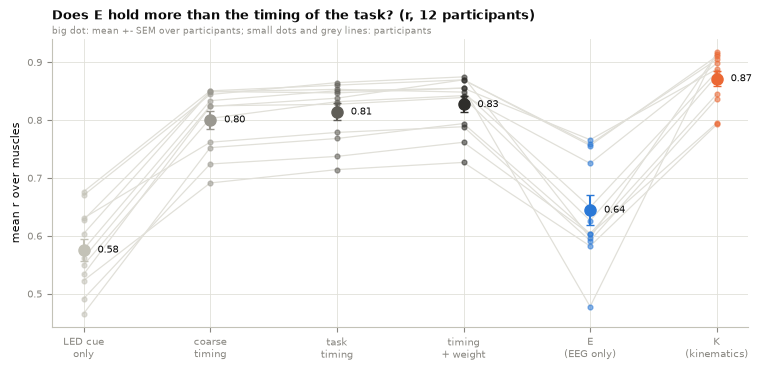

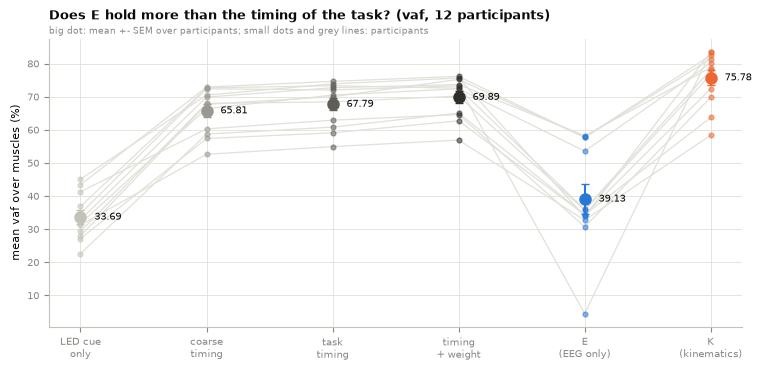

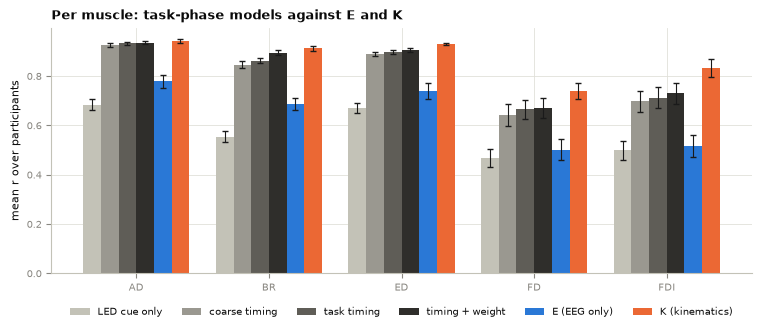

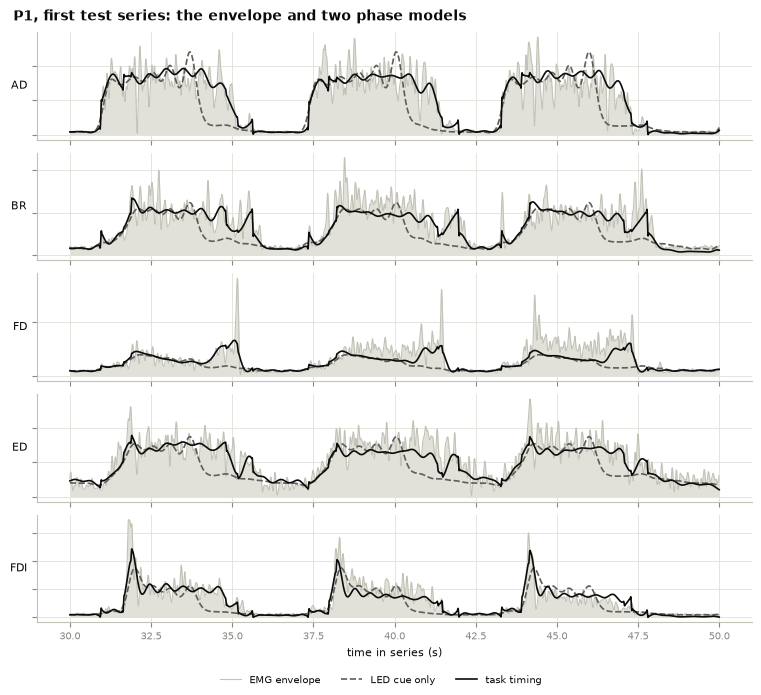

A1/A2: each participant's mean over muscles (grey lines) and the mean over participants. E sits where its line falls.
A3: the same per muscle. A4: what a timing-only model already gets right on a real stretch of data.


In [12]:
# CTRL-A-PLOT
cmp = pd.read_csv(OUT / "phase" / "phase_vs_E.csv")
show(PP.phase_summary(cmp, "r"), "A1_phase_vs_E_r")
show(PP.phase_summary(cmp, "vaf"), "A2_phase_vs_E_vaf")
show(PP.phase_muscles(cmp, "r"), "A3_phase_per_muscle")
if "examples" in globals() and examples:                    # needs the RUN cell of this session
    p0 = PARTICIPANTS[0]
    names = PB.emg_channel_names(p0, PB.data_dir())
    show(PP.phase_example({v: examples[v]["pred"][0] for v in ("cue", "phase")}, examples["cue"]["target"][0], names,
                          title=f"P{p0}, first test series: the envelope and two phase models"), "A4_phase_example")
print("A1/A2: each participant's mean over muscles (grey lines) and the mean over participants. E sits where its line falls.")
print("A3: the same per muscle. A4: what a timing-only model already gets right on a real stretch of data.")

## B. Reference maps: do the rollout maps of E agree with ERD and CMC?

Two model-free maps per participant, from all nine series:

- **ERD %** of alpha (8-13 Hz) and beta (13-30 Hz) power in the second before first touch and before lift-off,
  and in the hold, against the second before the hand starts (negative = desynchronisation).
- **CMC**: beta coherence (15-30 Hz) between each electrode and each muscle during the hold, from the raw EMG.

Each is correlated (Spearman, 32 electrodes) with the rollout maps of E from `outputs/interpretability_v2/`
(run the interpretability cell of `main_v2.ipynb` first). More desynchronisation should mean more importance, so
the ERD maps enter with their sign flipped (-ERD). **How to read it:** a positive mean rho with a small p says the
model reads the electrodes where the classical analyses see movement-related activity; rho near 0 says the maps
of E come from somewhere else (for example artefacts).

In [13]:
# CTRL-B-RUN
refs, cmps = [], []
for p in PARTICIPANTS:
    t0 = time.time()
    ref = RM.run_participant(p)
    refs.append(ref)
    cmps.append(pd.DataFrame(RM.compare(p, ref, PB.emg_channel_names(p, PB.data_dir()))))
    b = ref[(ref.kind == "erd") & (ref.band == "beta") & (ref.window == "lift_off")].set_index("electrode")["value"]
    c = ref[ref.kind == "cmc"].groupby("electrode")["value"].mean().sort_values(ascending=False)
    print(f"P{p}: strongest beta ERD at {', '.join(b.sort_values().index[:3])}; strongest CMC at {', '.join(c.index[:3])} "
          f"({time.time() - t0:.0f} s)")
ref_all, cmp_all = pd.concat(refs, ignore_index=True), pd.concat(cmps, ignore_index=True)
(OUT / "reference").mkdir(parents=True, exist_ok=True)
ref_all.to_csv(OUT / "reference" / "reference_maps.csv", index=False)
cmp_all.to_csv(OUT / "reference" / "rollout_vs_reference.csv", index=False)
group = pd.concat([RM.group_tables(ref_all, cmp_all), RM.group_map_rows(ref_all, PARTICIPANTS)], ignore_index=True)
group.to_csv(OUT / "reference" / "group.csv", index=False)
g = group[(group.event == "lift_off") & ((group.muscle == "mean") | group.muscle.isna())]
print()
print(g[["level", "view", "reference", "mean_rho", "n_positive", "n", "rho", "p"]].round(3).to_string(index=False))

P1: strongest beta ERD at C4, C3, CP5; strongest CMC at PO9, O1, PO10 (42 s)
P2: strongest beta ERD at C3, CP5, CP6; strongest CMC at C3, FC1, PO9 (55 s)
P3: strongest beta ERD at C3, CP6, P4; strongest CMC at O1, Oz, O2 (38 s)
P4: strongest beta ERD at CP1, C4, CP2; strongest CMC at CP1, C3, P3 (40 s)
P5: strongest beta ERD at C3, CP2, CP1; strongest CMC at Oz, PO9, Fp1 (45 s)
P6: strongest beta ERD at CP1, Pz, P4; strongest CMC at CP1, P3, CP2 (39 s)
P7: strongest beta ERD at C3, C4, CP1; strongest CMC at C3, CP5, CP1 (58 s)
P8: strongest beta ERD at C4, C3, CP1; strongest CMC at PO9, O1, Oz (50 s)
P9: strongest beta ERD at P3, C3, CP1; strongest CMC at PO10, C3, FC1 (34 s)
P10: strongest beta ERD at C4, CP1, P3; strongest CMC at F4, TP10, FC2 (35 s)
P11: strongest beta ERD at CP1, C3, C4; strongest CMC at PO10, FC2, O2 (37 s)
P12: strongest beta ERD at C3, CP1, C4; strongest CMC at PO10, C3, Oz (38 s)

       level      view           reference  mean_rho  n_positive    n   rho     p

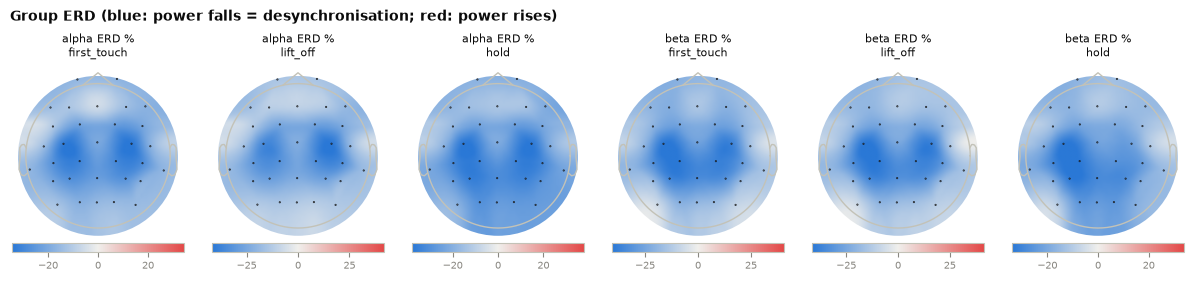

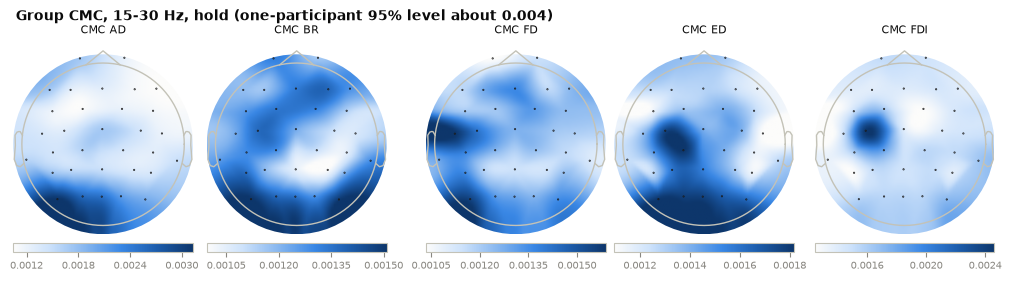

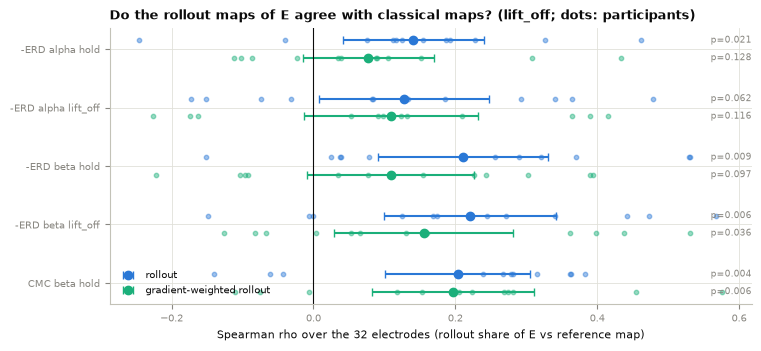

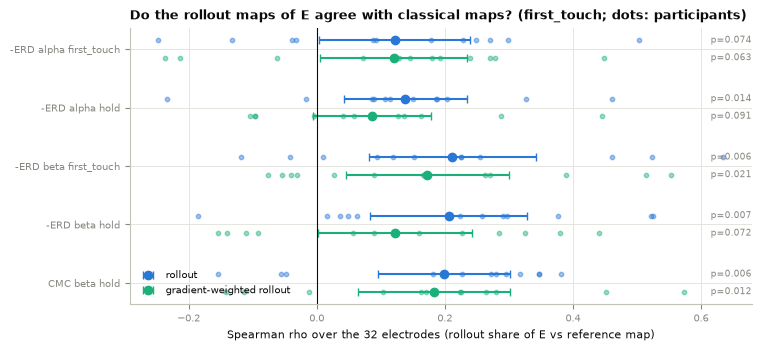

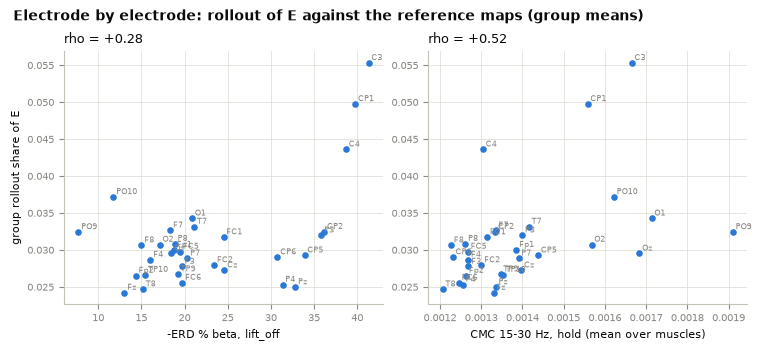

B1/B2: where the classical analyses see movement-related EEG (expect left central C3/CP for the right hand).
B3/B4: one dot per participant; the bar is the mean with its 95% interval; p = sign-flip test over participants.
B5: every electrode of the group maps; electrodes high on the y axis but low on the x axis are read by E
    without classical support (candidates for artefacts).


In [14]:
# CTRL-B-PLOT
ref_all = pd.read_csv(OUT / "reference" / "reference_maps.csv")
cmp_all = pd.read_csv(OUT / "reference" / "rollout_vs_reference.csv")
group = pd.read_csv(OUT / "reference" / "group.csv")
subjects = sorted({int(s[1:]) for s in ref_all.subject})
show(PP.erd_maps(ref_all), "B1_group_erd")
show(PP.cmc_maps(ref_all), "B2_group_cmc")
show(PP.rollout_vs_reference(cmp_all, group, "lift_off"), "B3_rollout_vs_reference_lift_off")
show(PP.rollout_vs_reference(cmp_all, group, "first_touch"), "B4_rollout_vs_reference_first_touch")
show(PP.rollout_reference_scatter(ref_all, RM.rollout_group(subjects, "lift_off", "rollout")), "B5_electrode_scatter")
print("B1/B2: where the classical analyses see movement-related EEG (expect left central C3/CP for the right hand).")
print("B3/B4: one dot per participant; the bar is the mean with its 95% interval; p = sign-flip test over participants.")
print("B5: every electrode of the group maps; electrodes high on the y axis but low on the x axis are read by E")
print("    without classical support (candidates for artefacts).")

## C. Forecast horizon: does the EEG help ahead of time?

Movement-related EEG changes (beta/mu desynchronisation) start about 1 s before the hand moves, while the
kinematics are still flat. KG-GT v2 is retrained with `model.causal`, `tokens.causal` (each output and each input
token uses past samples only; see `v2/causal.py`) and `tokens.horizon` (input token t predicts the envelope at
t + h). Per horizon and participant: accuracy of K, E and F, the residual test, and the EEG gain per task phase.
`pre_move` (the last second before the hand starts) is the phase where the EEG should help if it carries
intention.

**Cost:** 20-30 min per participant and horizon on a GTX 1660 Ti (12 participants x 4 horizons is about 16-24 h).
Finished runs are skipped; an interrupted run resumes from its `last.pt`. Start with a few participants
(set `C_PARTICIPANTS`), look at the plots, then add the rest.

**How to read it:** the prediction is that the EEG gain (F - K, residual r, pre_move skill) **grows with h**. If it
stays at zero at every horizon, the EEG adds nothing even where the kinematics cannot see what is coming, which
makes the main negative result much stronger.

In [15]:
# CTRL-C-RUN   (trains: 20-30 min per participant and horizon)
C_PARTICIPANTS = PARTICIPANTS            # e.g. [1, 2, 3, 4] first
HORIZONS_MS = [0, 200, 500, 1000]
args = SimpleNamespace(results="results/v2_horizon", checkpoints="outputs/checkpoints_v2_horizon",
                       smoke=False, amp=False, overwrite=False)
for h in HORIZONS_MS:
    for p in C_PARTICIPANTS:
        RH.run_one(p, h, args, device)
summary = RH.summarise(Path(args.results))

P1 h=0 ms: results exist, skipped (results\v2_horizon\h0ms\P1)
P2 h=0 ms: results exist, skipped (results\v2_horizon\h0ms\P2)
P3 h=0 ms: results exist, skipped (results\v2_horizon\h0ms\P3)
P4 h=0 ms: results exist, skipped (results\v2_horizon\h0ms\P4)


  Epochs:  50%|█████     | 75/150 [14:54<15:21, 12.29s/ep, tr=0.4157, valK=0.1073, valE=0.3184, badK=30/30, badE=2/30, badVK=2/30] 

  epoch  75: K frozen at its best epoch 45 (no improvement for 30 epochs)
  epoch  75: E + fusion now train against the frozen K (their patience starts again)


  Epochs:  71%|███████   | 106/150 [20:18<08:25, 11.49s/ep, tr=0.4135, valK=0.1070, valE=0.3173, badK=30/30, badE=30/30, badVK=20/30]


  epoch 107: E + fusion frozen at its best epoch 77 (no improvement for 30 epochs)
  early stop: both streams are frozen (K at epoch 75, E + fusion at epoch 107)
  combined best model: val K 0.1070  val E+F 0.3128  (K from epoch 45, E and fusion from epoch 77: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2_horizon\h0ms\P5  (best.pt, last.pt, history.json, metrics.*)
P5 h=0 ms: VAF K 63.0, F - K +0.27, E r 0.486; residual r tokens 0.109 (p 0.01); pre_move skill ridge +0.067, F +0.030; 21.0 min


...

  epoch  66: K frozen at its best epoch 36 (no improvement for 30 epochs)
  epoch  66: E + fusion now train against the frozen K (their patience starts again)


  Epochs:  47%|████▋     | 70/150 [28:13<44:28, 33.35s/ep, tr=0.4443, valK=0.1033, valE=0.4195, badK=30/30, badE=0/30, badVK=0/30] 

  [best.pt] ep   70  val K 0.1033 (best K ep 36)  val E+F 0.4195 (best E ep 70)


  Epochs:  67%|██████▋   | 100/150 [43:19<21:39, 25.99s/ep, tr=0.4217, valK=0.1033, valE=0.4262, badK=30/30, badE=30/30, badVK=30/30]


  epoch 101: E + fusion frozen at its best epoch 71 (no improvement for 30 epochs)
  early stop: both streams are frozen (K at epoch 66, E + fusion at epoch 101)
  combined best model: val K 0.1033  val E+F 0.4123  (K from epoch 36, E and fusion from epoch 71: the fusion was not validated with this K during training)
  checkpoints -> outputs\checkpoints_v2_horizon\h1000ms\P12  (best.pt, last.pt, history.json, metrics.*)
P12 h=1000 ms: VAF K 58.9, F - K +0.76, E r 0.319; residual r tokens 0.130 (p 0.01); pre_move skill ridge -0.099, F -0.029; 44.2 min

mean over participants, per horizon:
             n   K_vaf  F_minus_K_vaf    E_r  res_r_tokens  n_res_sig  pre_move_skill_ridge  n_pre_sig  pre_move_skill_F
horizon_ms                                                                                                              
0           12  75.477          0.084  0.562         0.083         11                -0.003          6             0.013
200         12  70.941          0.241  0.5


mean over participants, per horizon:
             n   K_vaf  F_minus_K_vaf    E_r  res_r_tokens  n_res_sig  pre_move_skill_ridge  n_pre_sig  pre_move_skill_F
horizon_ms                                                                                                              
0           12  75.477          0.084  0.562         0.083         11                -0.003          6             0.013
200         12  70.941          0.241  0.549         0.092         11                -0.002          6             0.003
500         12  66.226          0.546  0.530         0.089         12                -0.040          2            -0.017
1000        12  55.473          0.399  0.439         0.095          9                -0.032          3             0.012


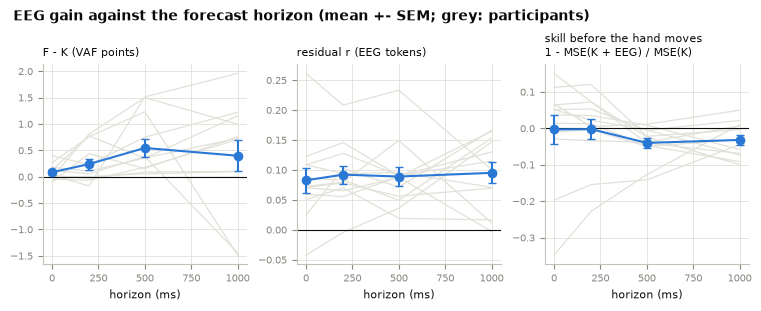

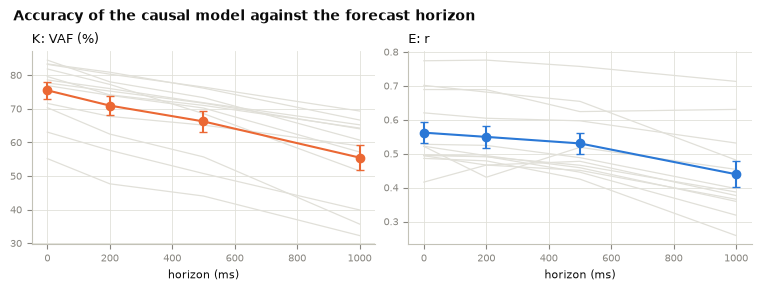

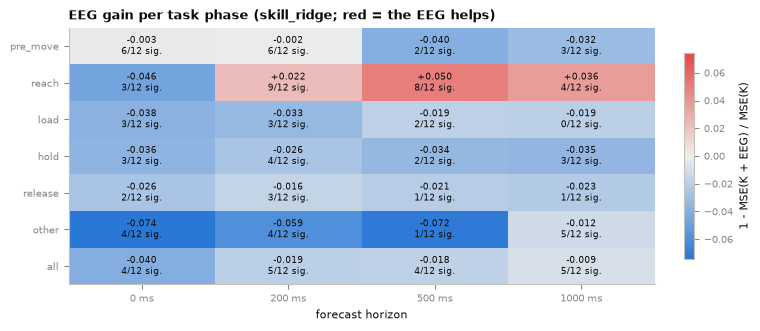

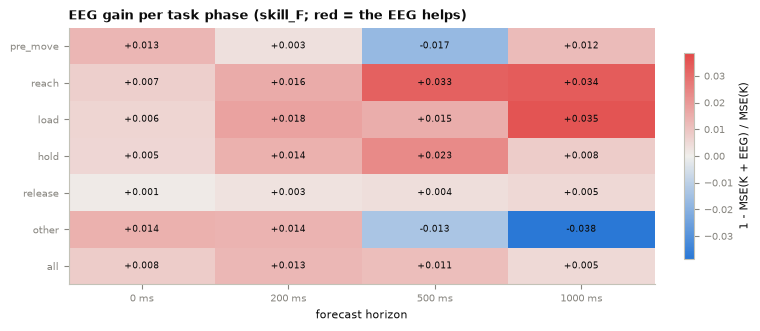

C1: F - K and the residual r over the whole test set, and the skill before the hand moves; grey lines are participants.
C2: how much accuracy forecasting costs (K should fall with h; E shows whether the EEG output holds up).
C3/C4: the EEG gain per task phase and horizon; 'x/n sig.' counts participants with p <= 0.05 and a positive gain.


In [17]:
# CTRL-C-PLOT
results_dir = Path("results/v2_horizon")
summary = RH.summarise(results_dir)
show(PP.horizon_gain(summary), "C1_eeg_gain_vs_horizon")
show(PP.horizon_accuracy(summary), "C2_accuracy_vs_horizon")
show(PP.horizon_segments(results_dir, "skill_ridge"), "C3_gain_per_phase_ridge")
show(PP.horizon_segments(results_dir, "skill_F"), "C4_gain_per_phase_F")
print("C1: F - K and the residual r over the whole test set, and the skill before the hand moves; grey lines are participants.")
print("C2: how much accuracy forecasting costs (K should fall with h; E shows whether the EEG output holds up).")
print("C3/C4: the EEG gain per task phase and horizon; 'x/n sig.' counts participants with p <= 0.05 and a positive gain.")